# Environmental and Vector Analysis Pipeline (CDM)
## Lagged correlation between climate and vector abundance in a selected study area

### 1. Setup and Imports

In [3]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text
import geopandas as gpd
from shapely import wkt
import contextily as ctx
import warnings
import os
warnings.filterwarnings('ignore')

# Add project root to path
project_root = Path.cwd().parent
sys.path.append(str(project_root))

from database.session import engine
from database.models import DimLocation, DimTime, FactEnvironmental, FactVectorObservation, DimVector

# Global output path for figures
FIGURE_OUTPUT_PATH = "/mnt/monadworld/projects/phd/article_manuscripts/new/figures"
os.makedirs(FIGURE_OUTPUT_PATH, exist_ok=True)
print(f"Figures will be saved to: {FIGURE_OUTPUT_PATH}")

# Plotting style
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

Figures will be saved to: /mnt/monadworld/projects/phd/article_manuscripts/new/figures


### 2. Configuration

In [4]:
# ===== CONFIGURATION =====
STUDY_REGION = "Siaya"   # Name as in dim_location.name  ---Greater Accra
VECTOR_SPECIES_PATTERN = "%gambiae%"  # SQL LIKE pattern (case-sensitive? depends on DB)
MAX_LAG_MONTHS = 6

print(f"Analysis Configuration:")
print(f"- Region: {STUDY_REGION}")
print(f"- Vector species pattern: {VECTOR_SPECIES_PATTERN}")
print(f"- Max lag: {MAX_LAG_MONTHS} months")

Analysis Configuration:
- Region: Siaya
- Vector species pattern: %gambiae%
- Max lag: 6 months


### 3. Check available vector species

In [5]:
species_query = "SELECT vector_code, species_name FROM dim_vector"
df_species = pd.read_sql(species_query, engine)
print("Available vector species in database:")
print(df_species.to_string(index=False))
if df_species.empty:
    raise ValueError("No vector species found in dim_vector. Load vocabulary first.")

Available vector species in database:
vector_code                  species_name
      ANGAM             Anopheles gambiae
      AEDAE                 Aedes aegypti
     ANOGAM Anopheles gambiae Giles, 1900


### 4. Load region code and link child locations

In [6]:
# Get region code
region_query = "SELECT location_code FROM dim_location WHERE name = :region_name"
region_df = pd.read_sql(text(region_query), engine, params={'region_name': STUDY_REGION})
if region_df.empty:
    raise ValueError(f"Region '{STUDY_REGION}' not found in dim_location")
region_code = region_df.iloc[0]['location_code']
print(f"Region code: {region_code}")

# Find point locations that have this region as parent
parent_query = """
SELECT location_code FROM dim_location
WHERE parent_location_code = :region_code
"""
child_codes_df = pd.read_sql(text(parent_query), engine, params={'region_code': region_code})
child_codes = child_codes_df['location_code'].tolist()
print(f"Found {len(child_codes)} point locations already linked to {STUDY_REGION}")

# If none, try spatial assignment
if not child_codes:
    print("\n⚠️ No point locations have parent_location_code set. Attempting spatial assignment...")
    from shapely import wkt
    from database.session import SessionLocal
    from database.models import DimLocation
    db = SessionLocal()
    region = db.query(DimLocation).filter(DimLocation.name == STUDY_REGION).first()
    if region and region.geometry_wkt:
        region_geom = wkt.loads(region.geometry_wkt)
        points = db.query(DimLocation).filter(DimLocation.admin_level == 'site').all()
        updated = 0
        for pt in points:
            if pt.geometry_wkt:
                point_geom = wkt.loads(pt.geometry_wkt)
                if point_geom.within(region_geom):
                    pt.parent_location_code = region_code
                    updated += 1
        db.commit()
        print(f"Assigned {updated} points to region {STUDY_REGION}")
        # Re-fetch
        child_codes_df = pd.read_sql(text(parent_query), engine, params={'region_code': region_code})
        child_codes = child_codes_df['location_code'].tolist()
    db.close()

# Include the region itself (in case it has direct observations)
all_location_codes = child_codes + [region_code]
print(f"Total location codes for analysis: {len(all_location_codes)}")

Region code: siaya
Found 0 point locations already linked to Siaya

⚠️ No point locations have parent_location_code set. Attempting spatial assignment...
Assigned 6 points to region Siaya
Total location codes for analysis: 7


### 5. Load monthly vector abundance

In [7]:
if not all_location_codes:
    raise ValueError("No location codes found for the study area.")

# Build SQL placeholders
placeholders = ','.join([f':code_{i}' for i in range(len(all_location_codes))])
params = {f'code_{i}': code for i, code in enumerate(all_location_codes)}
params['species_pattern'] = VECTOR_SPECIES_PATTERN

vec_query = f"""
SELECT 
    v.date_id,
    SUM(v.count) as total_count
FROM fact_vector_observation v
JOIN dim_vector dv ON v.vector_code = dv.vector_code
WHERE v.location_code IN ({placeholders})
  AND dv.species_name LIKE :species_pattern
GROUP BY v.date_id
ORDER BY v.date_id
"""
df_vec = pd.read_sql(text(vec_query), engine, params=params)
df_vec['date'] = pd.to_datetime(df_vec['date_id'])
print(f"Vector data: {len(df_vec)} months with observations")
if df_vec.empty:
    print("No vector data found. Possible reasons:")
    print("  - Species pattern does not match any species in dim_vector.")
    print("  - No vector observations for the selected location codes.")
    print("  - Vector observations exist but date_id is NULL or out of range.")
    print("\nConsider adjusting VECTOR_SPECIES_PATTERN. Example patterns: '%gambiae%', 'Anopheles gambiae', etc.")
else:
    print(f"Date range: {df_vec['date_id'].min()} to {df_vec['date_id'].max()}")

Vector data: 20 months with observations
Date range: 1968-07-01 to 2013-06-01


### 6. Load monthly environmental data (pivoted)

In [8]:
env_query = f"""
SELECT 
    date_id,
    MAX(CASE WHEN variable = 'temperature_mean' THEN value END) as temperature_mean,
    MAX(CASE WHEN variable = 'rainfall_total' THEN value END) as rainfall_total
FROM fact_environmental
WHERE location_code = :region_code
GROUP BY date_id
ORDER BY date_id
"""
df_env = pd.read_sql(text(env_query), engine, params={'region_code': region_code})
df_env['date'] = pd.to_datetime(df_env['date_id'])
print(f"Environmental data: {len(df_env)} months")
if df_env.empty:
    print("No environmental data found for the region.")

Environmental data: 1828 months


### 7. Merge datasets

In [9]:
if df_vec.empty or df_env.empty:
    raise ValueError("Insufficient data: vector or environmental dataset is empty. Cannot proceed.")

df_merged = pd.merge(df_vec, df_env, on='date_id', how='inner')
print(f"Overlapping months: {len(df_merged)}")
if df_merged.empty:
    raise ValueError("No overlapping months between vector and environmental data.")

df_merged['date'] = pd.to_datetime(df_merged['date_id'])
df_merged.set_index('date', inplace=True)
df_merged.sort_index(inplace=True)

print(f"Analysis period: {df_merged.index.min().date()} to {df_merged.index.max().date()}")
print(df_merged[['total_count', 'temperature_mean', 'rainfall_total']].head())

Overlapping months: 0


ValueError: No overlapping months between vector and environmental data.

### 8. Create lagged variables

In [10]:
for lag in range(1, MAX_LAG_MONTHS + 1):
    df_merged[f'temp_lag_{lag}'] = df_merged['temperature_mean'].shift(lag)
    df_merged[f'rain_lag_{lag}'] = df_merged['rainfall_total'].shift(lag)

df_clean = df_merged.dropna()
print(f"Rows after removing lags: {len(df_clean)}")
if len(df_clean) < 3:
    raise ValueError("Too few data points for correlation analysis after applying lags.")

Rows after removing lags: 0


ValueError: Too few data points for correlation analysis after applying lags.

### 9. Correlation analysis

In [48]:
# Contemporaneous correlations
corr_contemp = df_clean[['total_count', 'temperature_mean', 'rainfall_total']].corr()
print("\n=== CONTEMPORANEOUS CORRELATIONS ===")
print(corr_contemp.round(3))

# Lagged correlations
lag_cols = [f'temp_lag_{l}' for l in range(1, MAX_LAG_MONTHS+1)] + [f'rain_lag_{l}' for l in range(1, MAX_LAG_MONTHS+1)]
corr_lagged = df_clean[['total_count'] + lag_cols].corr()
print("\n=== LAGGED CORRELATIONS WITH ABUNDANCE ===")
print(corr_lagged['total_count'].drop('total_count').round(3))


=== CONTEMPORANEOUS CORRELATIONS ===
                  total_count  temperature_mean  rainfall_total
total_count               NaN               NaN             NaN
temperature_mean          NaN               NaN             NaN
rainfall_total            NaN               NaN             NaN

=== LAGGED CORRELATIONS WITH ABUNDANCE ===
temp_lag_1   NaN
temp_lag_2   NaN
temp_lag_3   NaN
temp_lag_4   NaN
temp_lag_5   NaN
temp_lag_6   NaN
rain_lag_1   NaN
rain_lag_2   NaN
rain_lag_3   NaN
rain_lag_4   NaN
rain_lag_5   NaN
rain_lag_6   NaN
Name: total_count, dtype: float64


### 10. Time series visualisation

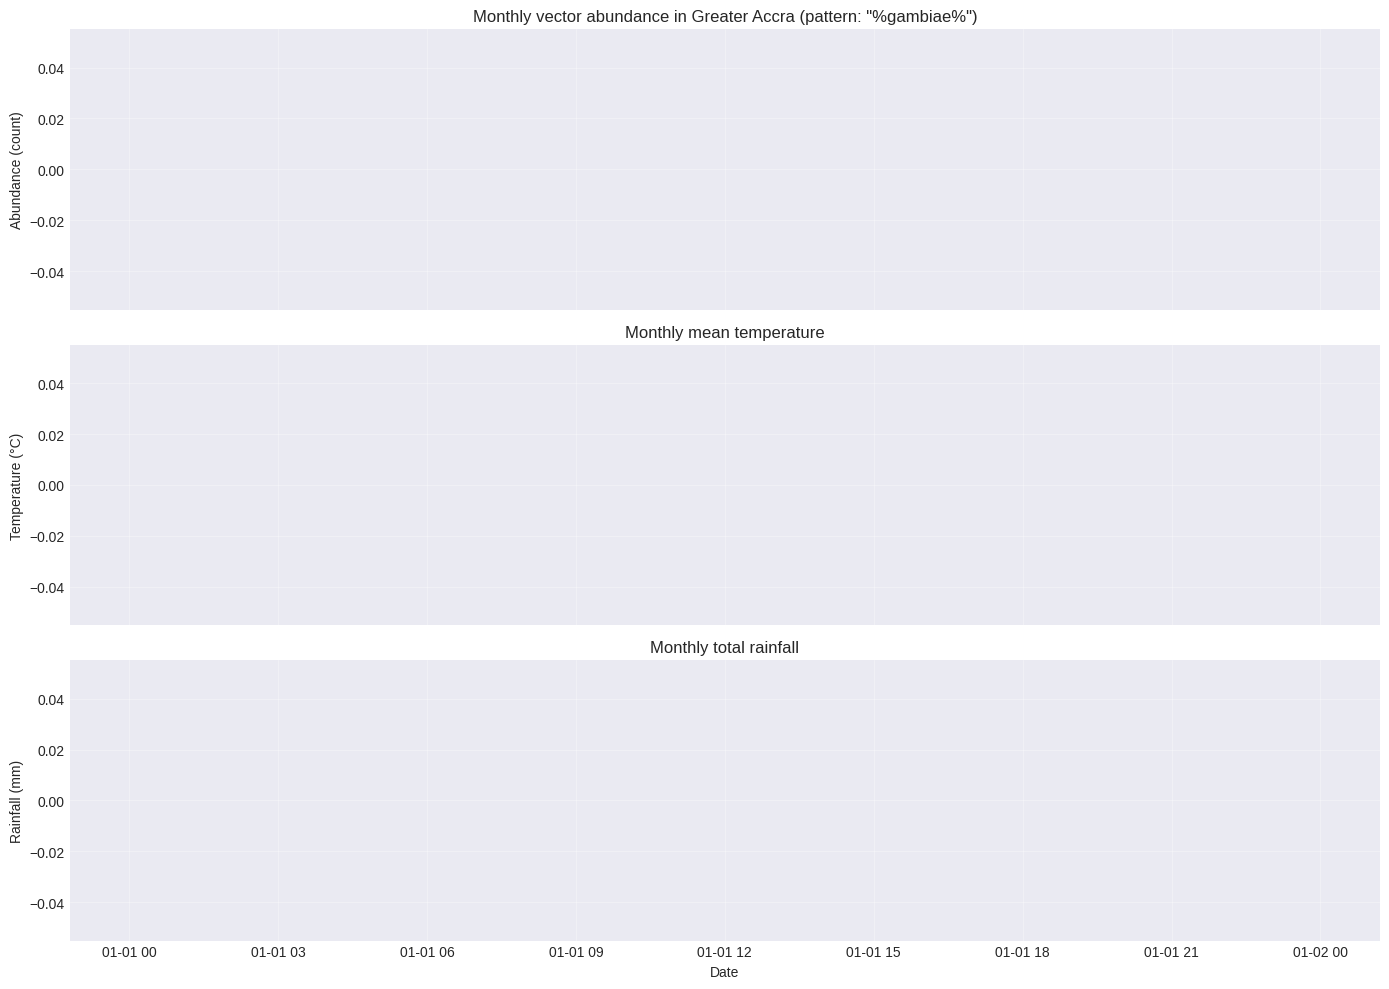

In [49]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

# Abundance
axes[0].plot(df_clean.index, df_clean['total_count'], marker='o', linestyle='-', color='#2E86AB')
axes[0].set_ylabel('Abundance (count)')
axes[0].set_title(f'Monthly vector abundance in {STUDY_REGION} (pattern: "{VECTOR_SPECIES_PATTERN}")')
axes[0].grid(True, alpha=0.3)

# Temperature
axes[1].plot(df_clean.index, df_clean['temperature_mean'], marker='s', color='#A23B72')
axes[1].set_ylabel('Temperature (°C)')
axes[1].set_title('Monthly mean temperature')
axes[1].grid(True, alpha=0.3)

# Rainfall
axes[2].bar(df_clean.index, df_clean['rainfall_total'], width=20, color='#F18F01', alpha=0.7)
axes[2].set_ylabel('Rainfall (mm)')
axes[2].set_title('Monthly total rainfall')
axes[2].grid(True, alpha=0.3)

plt.xlabel('Date')
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_OUTPUT_PATH, 'time_series_plot.png'), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

### 11. Lagged correlation bar plot

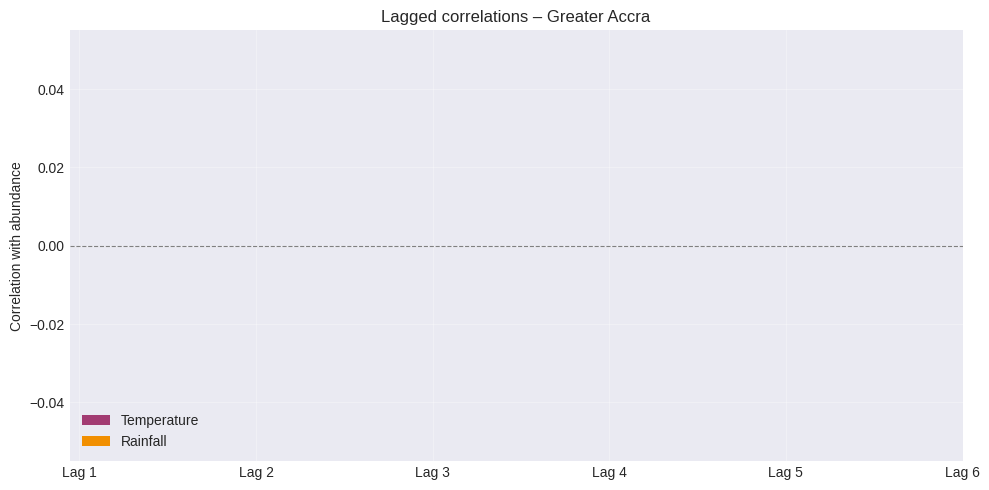

In [50]:
lags = range(1, MAX_LAG_MONTHS+1)
temp_corr = [corr_lagged.loc[f'temp_lag_{l}', 'total_count'] for l in lags]
rain_corr = [corr_lagged.loc[f'rain_lag_{l}', 'total_count'] for l in lags]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(lags))
width = 0.35
ax.bar(x - width/2, temp_corr, width, label='Temperature', color='#A23B72')
ax.bar(x + width/2, rain_corr, width, label='Rainfall', color='#F18F01')
ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels([f'Lag {l}' for l in lags])
ax.set_ylabel('Correlation with abundance')
ax.set_title(f'Lagged correlations – {STUDY_REGION}')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_OUTPUT_PATH, 'lagged_correlation_plot.png'), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

### 12. Summary statistics

In [51]:
print("\n" + "="*70)
print(f"SUMMARY STATISTICS - {STUDY_REGION}")
print("="*70)
print(f"\n📅 Analysis period: {df_clean.index.min().date()} to {df_clean.index.max().date()}")
print(f"📊 Number of months: {len(df_clean)}")
print(f"\n🦟 VECTOR ABUNDANCE:")
print(f"  • Mean: {df_clean['total_count'].mean():.1f} (±{df_clean['total_count'].std():.1f})")
print(f"  • Median: {df_clean['total_count'].median():.1f}")
print(f"  • Peak: {df_clean['total_count'].max()} ({df_clean['total_count'].idxmax().date()})")
print(f"\n🌡️ TEMPERATURE:")
print(f"  • Mean: {df_clean['temperature_mean'].mean():.1f}°C (±{df_clean['temperature_mean'].std():.1f})")
print(f"\n☔ RAINFALL:")
print(f"  • Mean monthly: {df_clean['rainfall_total'].mean():.1f} mm (±{df_clean['rainfall_total'].std():.1f})")
print(f"\n📈 BEST LAGGED CORRELATIONS:")
best_temp_lag = np.argmax(np.abs(temp_corr)) + 1
best_rain_lag = np.argmax(np.abs(rain_corr)) + 1
print(f"  • Temperature lag {best_temp_lag}: r = {temp_corr[best_temp_lag-1]:.3f}")
print(f"  • Rainfall lag {best_rain_lag}: r = {rain_corr[best_rain_lag-1]:.3f}")
print("="*70)


SUMMARY STATISTICS - Greater Accra

📅 Analysis period: NaT to NaT
📊 Number of months: 0

🦟 VECTOR ABUNDANCE:
  • Mean: nan (±nan)
  • Median: nan


ValueError: attempt to get argmax of an empty sequence